In [55]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display  

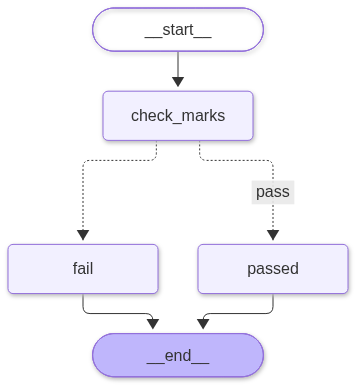

In [80]:
class State(TypedDict):
    name: str
    total_marks : int
    result : str
    
def check_marks(state: State):
    print("Checking marks for student: ", state['total_marks'])

def passed(state: State):
    return {"result" : "Congrulations you've passed the exam!!"} 

def fail(state: State):
    return {"result" : "Sorry you've failed the exam!!"}

def check_pass_fail(state: State):
    if state['total_marks'] >= 40:
        return "pass"
    else:
        return "fail"
    

graph = StateGraph(State)

graph.add_node("check_marks", check_marks)
graph.add_node("passed", passed)
graph.add_node("fail", fail)

graph.add_edge(START, "check_marks")
graph.add_conditional_edges("check_marks", check_pass_fail, {
    "pass": "passed",
    "fail": "fail"
})
graph.add_edge("passed", END)
graph.add_edge("fail", END)

graph_builder = graph.compile()

display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [81]:
graph_builder.invoke({"name": "John Doe", "total_marks": 75, "result": ""})

Checking marks for student:  75


{'name': 'John Doe',
 'total_marks': 75,
 'result': "Congrulations you've passed the exam!!"}